# Weather prediction-Ensemble Methods

https://www.kaggle.com/datasets/ananthr1/weather-prediction

# 2.**IMPORTING THE REQUIRED LIBRARIES**

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

# 3.**ANALYSING THE DATASET**

There are **6 Variables** in this Dataset:
* **4 Continuous** Variables.
* **1 Variable** to accommodate the Date.
* **1 Variable** refers the Weather.

In [ ]:
data=pd.read_csv("seattle-weather.csv")
data.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [ ]:
data.shape

(1461, 6)

As of it has **6 Columns** with total of **1461 Rows** as our observations in the Data set.

# 4.**DATA EXPLORATION**

It is the process of Exploring the data from the **"RAW"** data set tha we have taken or Imported.

First let us Deal with the Categorical variables

<ipython-input-9-70ea7a2c4c45>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="weather", data=data, palette="hls")


<Axes: xlabel='weather', ylabel='count'>

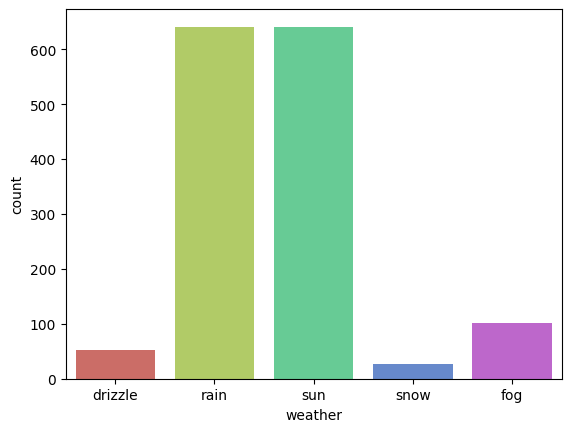

In [ ]:
import warnings
# warnings.filterwarnings('ignore')
sns.countplot(x="weather", data=data, palette="hls")

# 5.**NUMERICAL OR CONTINUOUS VARIABLES**

  Next we will explore the ***Continuous variables***

In [ ]:
data.describe()

,precipitation,temp_max,temp_min,wind
count,1461.000000,1461.000000,1461.000000,1461.000000
mean,3.029432,16.439083,8.234771,3.241136
std,6.680194,7.349758,5.023004,1.437825
min,0.000000,-1.600000,-7.100000,0.400000
25%,0.000000,10.600000,4.400000,2.200000
50%,0.000000,15.600000,8.300000,3.000000
75%,2.800000,22.200000,12.200000,4.000000
max,55.900000,35.600000,18.300000,9.500000


# 7.NULL VALUES:

In [ ]:
data.isna().sum()

date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64

# 8.DATA PREPROCESSING:

**Drop Unnecessary Variables**

In this data set Date is a unnecessary variable as it does not affect the data so it can be dropped.

In [ ]:
df=data.drop(["date"],axis=1)

In [ ]:
df.head()

,precipitation,temp_max,temp_min,wind,weather
0,0.0,12.8,5.0,4.7,drizzle
1,10.9,10.6,2.8,4.5,rain
2,0.8,11.7,7.2,2.3,rain
3,20.3,12.2,5.6,4.7,rain
4,1.3,8.9,2.8,6.1,rain


***Scaling the weather variables using label Encoder:***

In [ ]:
lc=LabelEncoder()
df["weather"]=lc.fit_transform(df["weather"])

In [ ]:
df.head()

,precipitation,temp_max,temp_min,wind,weather
0,0.0,12.8,5.0,4.7,0
1,10.9,10.6,2.8,4.5,2
2,0.8,11.7,7.2,2.3,2
3,20.3,12.2,5.6,4.7,2
4,1.3,8.9,2.8,6.1,2


In [ ]:
x=df[['precipitation','temp_max','temp_min','wind']]
y=df['weather']

***SPLITTING THE DATASET INTO DEPENDANT AND INDEPENDANT VARIABLES:***

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.1,random_state=2)

# 9.ALGORITHMS AND MODEL TRAINING:

[link text](https://)**K-NEAREST NEIGHBOR CLASSIFIER:**

** **bold text**Logistic Regression - CLASSIFIER:**

**Decision Tree Classifier:**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(x_train,y_train)
print(f"KNN accuracy:{round((knn.score(x_test,y_test)*100),1)}%")

KNN accuracy:78.2%


In [ ]:
from sklearn.linear_model import LogisticRegression
logreg=LogisticRegression()
logreg.fit(x_train,y_train)
score=logreg.score(x_test,y_test)
score

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8843537414965986

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()
dt.fit(x_train,y_train)
acc=dt.score(x_test,y_test)
acc

0.8163265306122449

# 10.CHECKING FOR THE USER INPUT:

In [ ]:
from sklearn.ensemble import VotingClassifier
ensemble=VotingClassifier(estimators=[('logreg',logreg),('knn',knn),('dt',dt)],voting='hard')
ensemble.fit(x,y)

In [ ]:
acc=ensemble.score(x_test,y_test)
acc

0.9183673469387755